<a href="https://colab.research.google.com/github/Kamal-Minocha/ucs420-/blob/main/assignment8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Question 1


In [8]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import Counter

# Downloading necessary NLTK data
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

paragraph = (
    "Artificial intelligence is transforming our world at an unprecedented pace. "
    "Machine learning algorithms enable computers to learn from vast amounts of data. "
    "Deep learning, a subset of machine learning, models human neural networks. "
    "These technologies power self-driving cars, smart assistants, and automated healthcare systems. "
    "As AI continues to evolve, ethical considerations become increasingly important. "
    "We must balance innovation with safety to ensure a beneficial future for humanity."
)

print("1.1 Convert to lowercase and remove punctuation")
lower_text = paragraph.lower()
clean_text = re.sub(r'[^a-zA-Z\s]', '', lower_text)
print("Cleaned Text:", clean_text)

print("\n1.2 Tokenize into words and sentences")
sentences = sent_tokenize(paragraph)
words = word_tokenize(paragraph)
print("Sentences Tokenized:", sentences)
print("Words Tokenized (first 10):", words[:10])

print("\n1.3 Compare python split() vs NLTK word_tokenize()")
python_split = paragraph.split()
print("Python split() first 10 tokens:", python_split[:10])
print("NLTK word_tokenize() first 10 tokens:", words[:10])
print("Difference:", "Python's split() splits strictly by whitespace and keeps punctuation attached to words (e.g., 'pace.'), whereas NLTK's word_tokenize() correctly separates punctuation from words (e.g., 'pace', '.').")

print("\n1.4 Remove stopwords")
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in word_tokenize(clean_text) if w not in stop_words]
print("Filtered Words (excluding stopwords):", filtered_words)

print("\n1.5 Word frequency distribution")
word_freq = Counter(filtered_words)
print("Word Frequency Distribution:", word_freq.most_common())

1.1 Convert to lowercase and remove punctuation
Cleaned Text: artificial intelligence is transforming our world at an unprecedented pace machine learning algorithms enable computers to learn from vast amounts of data deep learning a subset of machine learning models human neural networks these technologies power selfdriving cars smart assistants and automated healthcare systems as ai continues to evolve ethical considerations become increasingly important we must balance innovation with safety to ensure a beneficial future for humanity

1.2 Tokenize into words and sentences
Sentences Tokenized: ['Artificial intelligence is transforming our world at an unprecedented pace.', 'Machine learning algorithms enable computers to learn from vast amounts of data.', 'Deep learning, a subset of machine learning, models human neural networks.', 'These technologies power self-driving cars, smart assistants, and automated healthcare systems.', 'As AI continues to evolve, ethical considerations become

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


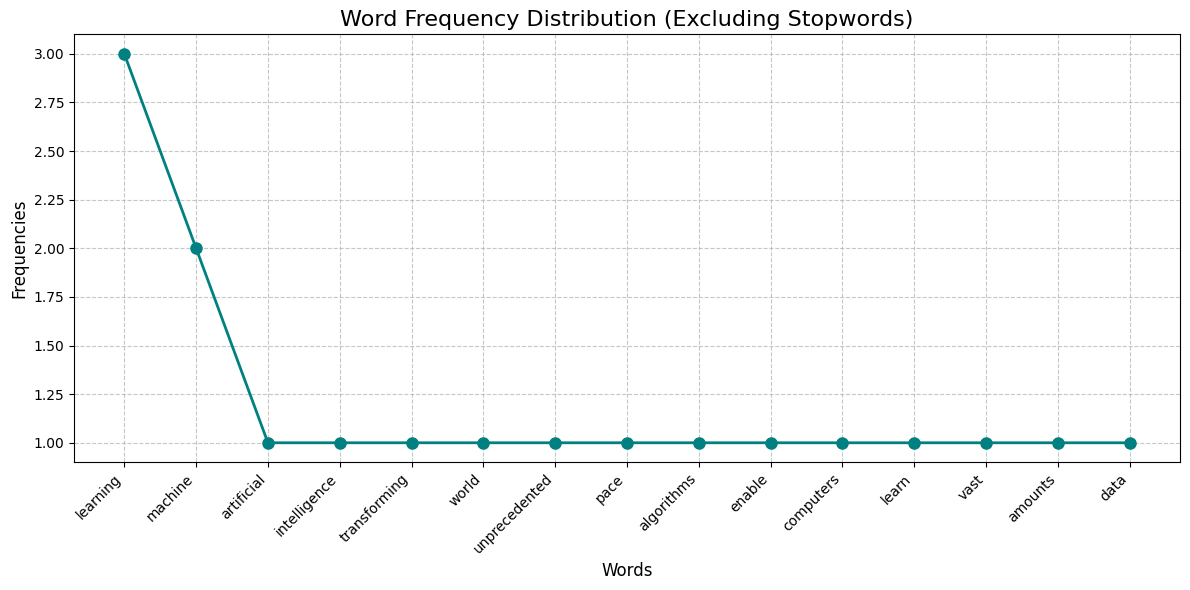

In [15]:
import matplotlib.pyplot as plt

# Extract terms and frequencies from the word_freq Counter created in Q1
words_labels, counts = zip(*word_freq.most_common(15))  # Plotting top 15 words

plt.figure(figsize=(12, 6))
plt.plot(words_labels, counts, color='teal', marker='o', linewidth=2, markersize=8)
plt.title('Word Frequency Distribution (Excluding Stopwords)', fontsize=16)
plt.xlabel('Words', fontsize=12)
plt.ylabel('Frequencies', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Question 2


In [9]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Ensure stop_words are loaded locally in this cell
try:
    stop_words = set(stopwords.words('english'))
except Exception:
    nltk.download('stopwords')
    stop_words = set(stopwords.words('english'))

print("2.1 Extract words with only alphabets")
alpha_words = re.findall(r'\b[a-zA-Z]+\b', paragraph.lower())
print("Alphabet only words (first 15):", alpha_words[:15])

print("\n2.2 Remove stopwords")
clean_alpha_words = [w for w in alpha_words if w not in stop_words]
print("Cleaned alphabet words:", clean_alpha_words[:15])

print("\n2.3Stemming with PorterStemmer")
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in clean_alpha_words]
print("Stemmed Words (first 15):", stemmed_words[:15])

print("\n2.4 Lemmatization with WordNetLemmatizer")
lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in clean_alpha_words]
print("Lemmatized Words (first 15):", lemmatized_words[:15])

print("\n2.5 Comparison and Explanation")
comparison = []
for w, s, l in zip(clean_alpha_words, stemmed_words, lemmatized_words):
    if s != l:
        comparison.append(f"{w} -> Stemmed: {s} | Lemmatized: {l}")
print("Differences detected:\n" + "\n".join(comparison[:10]))
print("\nExplanation:\n"
      "- Stemming uses crude heuristic rules to chop off prefixes/suffixes, which often leads to non-dictionary words (e.g., 'learning' -> 'learn', 'technologies' -> 'technolog').\n"
      "- Lemmatization uses vocabulary and morphological analysis (WordNet) to return valid base forms or lemmas (e.g., 'technologies' -> 'technology').\n"
      "- Prefer Stemming when speed and efficiency are key (like search index building). Prefer Lemmatization when context and grammatical correctness matter (like Chatbots, Q&A). ")

2.1 Extract words with only alphabets
Alphabet only words (first 15): ['artificial', 'intelligence', 'is', 'transforming', 'our', 'world', 'at', 'an', 'unprecedented', 'pace', 'machine', 'learning', 'algorithms', 'enable', 'computers']

2.2 Remove stopwords
Cleaned alphabet words: ['artificial', 'intelligence', 'transforming', 'world', 'unprecedented', 'pace', 'machine', 'learning', 'algorithms', 'enable', 'computers', 'learn', 'vast', 'amounts', 'data']

2.3Stemming with PorterStemmer
Stemmed Words (first 15): ['artifici', 'intellig', 'transform', 'world', 'unpreced', 'pace', 'machin', 'learn', 'algorithm', 'enabl', 'comput', 'learn', 'vast', 'amount', 'data']

2.4 Lemmatization with WordNetLemmatizer
Lemmatized Words (first 15): ['artificial', 'intelligence', 'transforming', 'world', 'unprecedented', 'pace', 'machine', 'learning', 'algorithm', 'enable', 'computer', 'learn', 'vast', 'amount', 'data']

2.5 Comparison and Explanation
Differences detected:
artificial -> Stemmed: artifici

# Question 3


In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

texts = [
    "The new smartphone has a fantastic OLED display and long-lasting battery life.",
    "The latest action movie was an absolute disaster with poor character development.",
    "Shares of major technology companies soared amid positive economic growth data."
]

print("=== Q3.1: CountVectorizer (Bag of Words) ===")
cv = CountVectorizer(stop_words='english')
bow_rep = cv.fit_transform(texts)
bow_df = pd.DataFrame(bow_rep.toarray(), columns=cv.get_feature_names_out())
print(bow_df)

print("\n=== Q3.2: TfidfVectorizer ===")
tfidf = TfidfVectorizer(stop_words='english')
tfidf_rep = tfidf.fit_transform(texts)
tfidf_df = pd.DataFrame(tfidf_rep.toarray(), columns=tfidf.get_feature_names_out())
print(tfidf_df.round(3))

print("\n=== Q3.3: Interpret Top 3 Keywords from each text ===")
feature_names = tfidf.get_feature_names_out()
for i, text in enumerate(texts):
    row = tfidf_df.iloc[i]
    top_indices = row.argsort()[::-1][:3]
    top_keywords = [(feature_names[idx], round(row.iloc[idx], 3)) for idx in top_indices]
    print(f"Text {i+1}: \"{text}\"")
    print(f"Top 3 Keywords: {top_keywords}\n")

=== Q3.1: CountVectorizer (Bag of Words) ===
   absolute  action  amid  battery  character  companies  data  development  \
0         0       0     0        1          0          0     0            0   
1         1       1     0        0          1          0     0            1   
2         0       0     1        0          0          1     1            0   

   disaster  display  ...  major  movie  new  oled  poor  positive  shares  \
0         0        1  ...      0      0    1     1     0         0       0   
1         1        0  ...      0      1    0     0     1         0       0   
2         0        0  ...      1      0    0     0     0         1       1   

   smartphone  soared  technology  
0           1       0           0  
1           0       0           0  
2           0       1           1  

[3 rows x 27 columns]

=== Q3.2: TfidfVectorizer ===
   absolute  action   amid  battery  character  companies   data  development  \
0     0.000   0.000  0.000    0.333      0.000

# Question 4


In [10]:
import re
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Ensure stop_words are loaded locally in this cell
try:
    stop_words = set(stopwords.words('english'))
except Exception:
    nltk.download('stopwords')
    stop_words = set(stopwords.words('english'))

text_ai = (
    "Artificial intelligence is a transformative technology focused on creating smart machines. "
    "It relies heavily on neural networks, machine learning algorithms, and deep learning architectures. "
    "AI systems learn from patterns in huge datasets to make complex predictions and decisions automatically. "
    "From natural language processing to computer vision, AI is reshaping modern industrial sectors."
)

text_blockchain = (
    "Blockchain is a decentralized and distributed ledger technology that securely records transactions. "
    "It establishes high trust across peer-to-peer networks without relying on central governing authorities. "
    "Using cryptographic hashing and consensus mechanisms, data within a blockchain remains immutable. "
    "Its prominent applications include secure financial smart contracts and global digital currencies."
)

print("4.1 Preprocess and Tokenize both texts")
def tokenize(text):
    clean = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    return [w for w in clean.split() if w not in stop_words]

tokens_ai = tokenize(text_ai)
tokens_blockchain = tokenize(text_blockchain)
print("AI Tokens:", tokens_ai[:10])
print("Blockchain Tokens:", tokens_blockchain[:10])

print("\n4.2a: Jaccard Similarity")
set_ai = set(tokens_ai)
set_bc = set(tokens_blockchain)
intersection = set_ai.intersection(set_bc)
union = set_ai.union(set_bc)
jaccard_sim = len(intersection) / len(union)
print(f"Jaccard Similarity: {jaccard_sim:.4f} (Common terms: {intersection})")

print("\n4.2b Cosine Similarity ")
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform([text_ai, text_blockchain])
cos_sim = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]
print(f"Cosine Similarity: {cos_sim:.4f}")

print("\n4.2c Similarity Metric Analysis ")
print("Cosine Similarity gives better insights here. Jaccard similarity is purely term-overlap based "
      "and ignores term importance, semantic meaning, and word frequencies, making it overly sensitive to syntax. "
      "Cosine similarity with TF-IDF weights down trivial terms and compares the spatial orientation of text vectors, "
      "offering a more robust semantic-like comparison.")

4.1 Preprocess and Tokenize both texts
AI Tokens: ['artificial', 'intelligence', 'transformative', 'technology', 'focused', 'creating', 'smart', 'machines', 'relies', 'heavily']
Blockchain Tokens: ['blockchain', 'decentralized', 'distributed', 'ledger', 'technology', 'securely', 'records', 'transactions', 'establishes', 'high']

4.2a: Jaccard Similarity
Jaccard Similarity: 0.0417 (Common terms: {'networks', 'technology', 'smart'})

4.2b Cosine Similarity 
Cosine Similarity: 0.1526

4.2c Similarity Metric Analysis 
Cosine Similarity gives better insights here. Jaccard similarity is purely term-overlap based and ignores term importance, semantic meaning, and word frequencies, making it overly sensitive to syntax. Cosine similarity with TF-IDF weights down trivial terms and compares the spatial orientation of text vectors, offering a more robust semantic-like comparison.


# Question 5


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


5.1 & 5.2 Sentiment Polarity, Subjectivity & Classification

Review 1: "I absolutely loved this product! It has amazing features, works flawlessly, and represents superb value for money."
Polarity Scores: {'neg': 0.0, 'neu': 0.399, 'pos': 0.601, 'compound': 0.9484} | Classified Sentiment: Positive

Review 2: "The service was terrible and the product arrived damaged. Very disappointed and would not recommend to anyone."
Polarity Scores: {'neg': 0.469, 'neu': 0.531, 'pos': 0.0, 'compound': -0.8886} | Classified Sentiment: Negative

Review 3: "It's an okay product. Performs as expected, nothing extraordinary, but satisfies the basic utility requirements."
Polarity Scores: {'neg': 0.172, 'neu': 0.745, 'pos': 0.083, 'compound': -0.3711} | Classified Sentiment: Negative

Review 4: "This is the best experience I have ever had! Phenomenal service, fast shipping, and extremely high quality."
Polarity Scores: {'neg': 0.0, 'neu': 0.77, 'pos': 0.23, 'compound': 0.6696} | Classified Sentiment: Posi

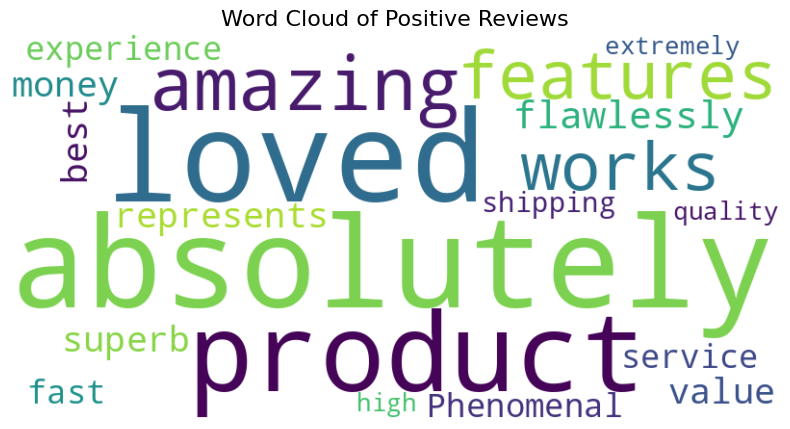

In [12]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Try importing VADER; if not available, install it
try:
    from nltk.sentiment.vader import SentimentIntensityAnalyzer
except ImportError:
    import os
    os.system('pip install nltk')
    from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon')

reviews = [
    "I absolutely loved this product! It has amazing features, works flawlessly, and represents superb value for money.",
    "The service was terrible and the product arrived damaged. Very disappointed and would not recommend to anyone.",
    "It's an okay product. Performs as expected, nothing extraordinary, but satisfies the basic utility requirements.",
    "This is the best experience I have ever had! Phenomenal service, fast shipping, and extremely high quality."
]

sia = SentimentIntensityAnalyzer()
positive_reviews_text = ""

print("5.1 & 5.2 Sentiment Polarity, Subjectivity & Classification")
for idx, rev in enumerate(reviews):
    scores = sia.polarity_scores(rev)
    compound = scores['compound']

    # Classify sentiment based on compound score
    if compound >= 0.05:
        sentiment = "Positive"
        positive_reviews_text += " " + rev
    elif compound <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"\nReview {idx+1}: \"{rev}\"")
    print(f"Polarity Scores: {scores} | Classified Sentiment: {sentiment}")

print("\n5.3 Word Cloud for Positive Reviews")
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate(positive_reviews_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Positive Reviews', fontsize=16)
plt.show()

# Question 6


In [13]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

training_data = (
    "Deep learning models are computing systems modeled after the structure of biological brains. "
    "These architectures are composed of multiple layers of neural nodes that processes vast information. "
    "The training process involves adjustments to internal parameters to reduce prediction errors on validation sets. "
    "By updating connection weights sequentially, the network improves its classification performance and features representation. "
    "Modern researchers apply generative models for computer vision, automated software generation, and creative text generation tasks. "
    "Through persistent optimization, neural language networks have shown a remarkable capability to generate coherent original text."
)

print("6.1 Tokenize using Keras Tokenizer")
tok = Tokenizer()
tok.fit_on_texts([training_data])
total_words = len(tok.word_index) + 1
print("Total Unique Words:", total_words)

print("\n6.2 Create sequences and build LSTM model")
input_sequences = []
for line in training_data.split('.'):
    token_list = tok.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

max_sequence_len = max([len(x) for x in input_sequences])
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))

X, y = input_sequences[:, :-1], input_sequences[:, -1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

# Build standard simple LSTM model
model = Sequential([
    Embedding(total_words, 32, input_length=max_sequence_len - 1),
    LSTM(64),
    Dense(total_words, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

print("\n6.3 Train model and Generate Text")
model.fit(X, y, epochs=150, verbose=0)  # Silence epochs for clean execution output

def generate_text(seed_word, next_words=10):
    result = seed_word
    for _ in range(next_words):
        token_list = tok.texts_to_sequences([result])[0]
        token_list = pad_sequences([token_list], maxlen=max_sequence_len - 1, padding='pre')
        predicted = np.argmax(model.predict(token_list, verbose=0), axis=-1)[0]
        output_word = ""
        for word, index in tok.word_index.items():
            if index == predicted:
                output_word = word
                break
        result += " " + output_word
    return result

seed = "neural"
generated = generate_text(seed, next_words=12)
print(f"Seed: \"{seed}\" -> Generated Text: \"{generated}\"")

6.1 Tokenize using Keras Tokenizer
Total Unique Words: 77

6.2 Create sequences and build LSTM model


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


6.3 Train model and Generate Text
Seed: "neural" -> Generated Text: "neural persistent optimization language language networks have shown a remarkable capability to generate"
